# Assignment 2a, forced alignment with the Montreal Forced Aligner

Runs `Assignment_2a/align.py` on a Colab CPU runtime (alignment needs no GPU). Each stage stops the notebook if it
fails.

1. **prepare** converts the six clips to 16 kHz WAV (three are NIST SPHERE files) and normalises the transcripts
2. **dictionaries** builds three lexicons for the 151 words (english_us_arpa with G2P for missing words, g2p_en as in
   Assignment 1, english_mfa with G2P for missing words)
3. **align** runs MFA four times (english_us_arpa with two lexicons, english_mfa, and english_us_arpa adapted to
   these clips)
4. **analyse** writes word and phone tables, alignment checks and the boundary differences between runs
5. **plot** draws Praat style figures

The code and the provided clips come from the private dataset repo `gsri-18/ltrc-a2-data`, and the outputs go
back to it as `results/A2a_outputs.zip`.

**Unattended run.** Choose Run all, then answer the two prompts at the start (the Hugging Face token, or a Colab
secret named `HF_TOKEN`, and the Google Drive permission). After that nothing needs watching. Every cell and every
log line carries its IST time. When the last cell finishes, or a cell fails, or the run passes 1.5 h, the
notebook saves itself with all outputs, the logs and the results to Hugging Face (`gsri-18/ltrc-a2-data`,
`results/A2a/`) and Google Drive (`MyDrive/LTRC_Assignment2/A2a/`), and then disconnects and deletes the
runtime. Interrupting a cell by hand does not disconnect.

In [1]:
TAG = "A2a"
DATA_REPO = "gsri-18/ltrc-a2-data"
MAX_HOURS = 1.5   # if still running after this, save everything and disconnect anyway

import datetime, json, os, shutil, threading, time

IST = datetime.timezone(datetime.timedelta(hours=5, minutes=30))
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
LOG_DIR = "/content/session_logs"
os.makedirs(LOG_DIR, exist_ok=True)
DRIVE_DIR = None        # MyDrive/LTRC_Assignment2/<TAG>, set below when Google Drive is mounted
ARTIFACTS = []          # result zips, copied to Drive as they are made


def now():
    return datetime.datetime.now(IST).strftime("%Y-%m-%d %H:%M:%S")


def log(msg):
    line = f"[{now()} IST] {msg}"
    print(line, flush=True)
    with open(f"{LOG_DIR}/session_log.txt", "a") as f:
        f.write(line + "\n")


def save_notebook():
    """The notebook as it is at this moment, with every output so far."""
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
        with open(f"{LOG_DIR}/{TAG}_executed.ipynb", "w") as f:
            json.dump(nb, f)
        log(f"exported the notebook with its outputs ({len(nb['cells'])} cells)")
    except Exception as e:
        log(f"could not export the notebook ({type(e).__name__} {e})")


def to_drive(path):
    if DRIVE_DIR and os.path.exists(path):
        try:
            if os.path.isdir(path):
                shutil.copytree(path, f"{DRIVE_DIR}/{os.path.basename(path)}_{STAMP}", dirs_exist_ok=True)
            else:
                shutil.copy(path, DRIVE_DIR)
        except Exception as e:
            log(f"Drive copy of {path} failed ({type(e).__name__} {e})")


def save_everything(status):
    with open(f"{LOG_DIR}/status.json", "w") as f:
        json.dump({"notebook": TAG, "status": status, "started": f"{START:%Y-%m-%d %H:%M:%S} IST",
                   "ended": f"{now()} IST", "minutes": round((time.time() - START.timestamp()) / 60, 1)}, f, indent=1)
    save_notebook()
    try:
        from huggingface_hub import HfApi
        HfApi().upload_folder(folder_path=LOG_DIR, path_in_repo=f"results/{TAG}/session_{STAMP}", repo_id=DATA_REPO,
                              repo_type="dataset", commit_message=f"{TAG} session {STAMP} {status}")
        log(f"saved the logs and the notebook to {DATA_REPO}/results/{TAG}/session_{STAMP}")
    except Exception as e:
        log(f"Hugging Face upload of the logs failed ({type(e).__name__} {e})")
    if DRIVE_DIR:
        for p in ARTIFACTS:
            to_drive(p)
        to_drive(LOG_DIR)
        try:
            from google.colab import drive
            drive.flush_and_unmount()
            log(f"saved everything to Google Drive {DRIVE_DIR}")
        except Exception as e:
            log(f"Drive flush failed ({type(e).__name__} {e})")


_done = threading.Lock()


def finish(status="completed"):
    """Save everything to Hugging Face and Drive, then disconnect and delete the runtime."""
    if not _done.acquire(blocking=False):
        return
    log(f"notebook {status} after {(time.time() - START.timestamp()) / 60:.1f} min, saving")
    save_everything(status)
    log("disconnecting and deleting the runtime")
    time.sleep(3)
    from google.colab import runtime
    runtime.unassign()


if "_session_hooks" not in globals():
    START = datetime.datetime.now(IST)
    STAMP = f"{START:%Y%m%d_%H%M%S}"

    def _cell_start(info):
        globals()["_cell_t0"] = time.time()
        globals()["_cell_first_line"] = (info.raw_cell.strip().splitlines() or [""])[0][:90]

    def _cell_end(result):
        took = time.time() - globals().get("_cell_t0", time.time())
        err = result.error_before_exec or result.error_in_exec
        status = "ok" if err is None else type(err).__name__
        print(f"[{now()} IST] finished in {took:.1f} s" + ("" if err is None else f", {status}"))
        path = f"{LOG_DIR}/cell_times.csv"
        new = not os.path.exists(path)
        with open(path, "a") as f:
            if new:
                f.write("finished_ist,seconds,status,first_line\n")
            f.write('{},{:.1f},{},"{}"\n'.format(now(), took, status, globals().get("_cell_first_line", "session setup").replace('"', "'")))
        if err is not None and not isinstance(err, KeyboardInterrupt):
            log(f"cell failed with {err!r}")
            finish("failed")

    get_ipython().events.register("pre_run_cell", _cell_start)
    get_ipython().events.register("post_run_cell", _cell_end)
    _watchdog = threading.Timer(MAX_HOURS * 3600, finish, args=(f"stopped by the {MAX_HOURS} h limit",))
    _watchdog.daemon = True
    _watchdog.start()
    _session_hooks = True
    log(f"session started, {TAG}, everything is saved and the runtime deleted at the end, after an error "
        f"or after {MAX_HOURS} h")

[2026-11-17 23:54:25 IST] session started, A2a, everything is saved and the runtime deleted at the end, after an error or after 1.5 h
[2026-11-17 23:54:25 IST] finished in -0.0 s


In [2]:
import getpass, requests
from huggingface_hub import whoami


def can_write(token):
    """Asks the data repo how a small file would be uploaded, which needs write access and commits nothing."""
    r = requests.post(f"https://huggingface.co/api/datasets/{DATA_REPO}/preupload/main", timeout=30,
                      headers={"authorization": f"Bearer {token}"},
                      json={"files": [{"path": "results/write_check.txt", "size": 4, "sample": "dGVzdA=="}]})
    return r.status_code == 200


token = os.environ.get("HF_TOKEN", "")
if not token:
    try:
        from google.colab import userdata          # a Colab secret named HF_TOKEN, if there is one
        token = userdata.get("HF_TOKEN") or ""
    except Exception:
        token = ""
if not token:
    token = getpass.getpass("Hugging Face token with write access ").strip()
if not can_write(token):                           # checked now, not after an hour of training
    raise PermissionError(f"this Hugging Face token has no write access to {DATA_REPO}, use a token with write "
                          "access (and update or delete the HF_TOKEN Colab secret if there is one)")
os.environ["HF_TOKEN"] = token
log(f"logged in to Hugging Face as {whoami()['name']}, with write access to {DATA_REPO}")

# Google Drive gets a second copy of everything. Declining the prompt keeps Hugging Face only.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = f"/content/drive/MyDrive/LTRC_Assignment2/{TAG}"
    os.makedirs(DRIVE_DIR, exist_ok=True)
    log(f"Google Drive mounted, copies go to MyDrive/LTRC_Assignment2/{TAG}")
except Exception as e:
    log(f"Google Drive not mounted ({type(e).__name__}), saving to Hugging Face only")

[2026-11-17 23:54:28 IST] logged in to Hugging Face as gsri-18, with write access to gsri-18/ltrc-a2-data
Mounted at /content/drive
[2026-11-17 23:54:52 IST] Google Drive mounted, copies go to MyDrive/LTRC_Assignment2/A2a
[2026-11-17 23:54:52 IST] finished in 27.3 s


## Setup

In [3]:
import zipfile
from huggingface_hub import hf_hub_download

for name, dst in [("code.zip", "/content/project"), ("A2a_data.zip", "/content/project/Assignment_2a")]:
    path = hf_hub_download(DATA_REPO, name, repo_type="dataset", force_download=(name == "code.zip"))
    zipfile.ZipFile(path).extractall(dst)
    log(f"{name} -> {dst}")
log("code version " + open("/content/project/COMMIT").read().strip())
!ls /content/project/Assignment_2a/data/*
!pip -q install "setuptools<81" tgt praat-parselmouth g2p_en

import re, subprocess, sys

PY = sys.executable  # Colab's Python, not the one in the aligner's environment


def run(cmd, keep=None, drop=None):
    """Run a shell command, print its filtered output with the time of each line, keep a copy in
    session_logs/run_output.txt and raise if it fails."""
    log(f"$ {cmd}")
    with open(f"{LOG_DIR}/run_output.txt", "a") as out:
        out.write(f"\n[{now()} IST] $ {cmd}\n")
        proc = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in proc.stdout:
            for part in line.replace("\r", "\n").split("\n"):
                if part.strip() and (not keep or re.search(keep, part)) and not (drop and re.search(drop, part)):
                    stamped = f"[{datetime.datetime.now(IST):%H:%M:%S}] {part}"
                    print(stamped, flush=True)
                    out.write(stamped + "\n")
        code = proc.wait()
    if code != 0:
        raise RuntimeError(f"{cmd} failed with exit code {code}")

[2026-11-17 23:54:54 IST] code.zip -> /content/project
[2026-11-17 23:54:57 IST] A2a_data.zip -> /content/project/Assignment_2a
[2026-11-17 23:54:57 IST] code version b8e0c73
/content/project/Assignment_2a/data/transcripts:
F2BJRLP1.TXT  ISLE_SESS0131_BLOCKD02_01_sprt1.txt
F2BJRLP2.TXT  ISLE_SESS0131_BLOCKD02_02_sprt1.txt
F2BJRLP3.TXT  ISLE_SESS0131_BLOCKD02_03_sprt1.txt

/content/project/Assignment_2a/data/wav:
F2BJRLP1.wav  ISLE_SESS0131_BLOCKD02_01_sprt1.wav
F2BJRLP2.wav  ISLE_SESS0131_BLOCKD02_02_sprt1.wav
F2BJRLP3.wav  ISLE_SESS0131_BLOCKD02_03_sprt1.wav
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[2026-11-17 23:55:06 IST] finished in 13.7 s


Montreal Forced Aligner gets its own micromamba environment, and only its `mfa` command is used.

In [4]:
%cd /content
run("curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba")
run("./bin/micromamba create -q -y -p /content/mfa_env -c conda-forge python=3.11 montreal-forced-aligner=3",
    drop=r".")
os.environ["PATH"] = "/content/mfa_env/bin:" + os.environ["PATH"]
os.environ["MFA_ROOT_DIR"] = "/content/mfa_root"
run("mfa version")

/content
[2026-11-17 23:55:06 IST] $ curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba
[2026-11-17 23:55:08 IST] $ ./bin/micromamba create -q -y -p /content/mfa_env -c conda-forge python=3.11 montreal-forced-aligner=3
[2026-11-17 23:57:03 IST] $ mfa version
[23:57:05] 3.4.4
[2026-11-17 23:57:05 IST] finished in 119.1 s


## Prepare

In [5]:
%cd /content/project/Assignment_2a
run(f"{PY} align.py --stage prepare")
!head -c 300 corpus/*/*.lab

/content/project/Assignment_2a
[2026-11-17 23:57:05 IST] $ /usr/bin/python3 align.py --stage prepare
[23:57:06] ==== prepare
[23:57:06] F2BJRLP1                               bu_f2b           25.31 s  73 words
[23:57:06] F2BJRLP2                               bu_f2b           28.65 s  74 words
[23:57:06] F2BJRLP3                               bu_f2b           30.71 s  82 words
[23:57:06] ISLE_SESS0131_BLOCKD02_01_sprt1        isle_sess0131     4.12 s  5 words
[23:57:06] ISLE_SESS0131_BLOCKD02_02_sprt1        isle_sess0131     3.88 s  5 words
[23:57:06] ISLE_SESS0131_BLOCKD02_03_sprt1        isle_sess0131     4.50 s  5 words
==> corpus/bu_f2b/F2BJRLP1.lab <==
wanted chief justice of the massachusetts supreme court in april the s j c's current leader edward hennessy reaches the mandatory retirement age of seventy and a successor is expected to be named in march it may be the most important appointment governor michael dukakis makes during the remainder of
==> corpus/bu_f2b/F2BJRLP2.lab <

## Dictionaries

In [6]:
run(f"{PY} align.py --stage dictionaries", drop=r"it/s|━")
!wc -l dictionaries/*.dict

[2026-11-17 23:57:06 IST] $ /usr/bin/python3 align.py --stage dictionaries
[23:57:06] ==== dictionaries
[23:57:06] downloading https://github.com/MontrealCorpusTools/mfa-models/releases/download/dictionary-english_us_arpa-v3.0.0/english_us_arpa.dict
[23:57:07] downloading https://github.com/MontrealCorpusTools/mfa-models/releases/download/g2p-english_us_arpa-v2.0.0a/english_us_arpa.zip
[23:57:08] $ /content/mfa_env/bin/mfa g2p /content/project/Assignment_2a/dictionaries/oov_english_us_arpa/words.txt english_us_arpa /content/project/Assignment_2a/dictionaries/oov_english_us_arpa/g2p.dict --clean --num_pronunciations 1 --temporary_directory /content/project/Assignment_2a/mfa_tmp/g2p_english_us_arpa
[23:57:13]  INFO     Generating pronunciations...                                          
[23:57:18]  INFO     Done! Everything took 8.051 seconds                                   
[23:57:26] [nltk_data] Downloading package averaged_perceptron_tagger to
[23:57:26] [nltk_data]     /root/nltk

## Align

In [7]:
run(f"{PY} align.py --stage align --num_jobs {os.cpu_count()}", keep=r"^\$|INFO|TextGrids|rror|Traceback|downloading")
!find outputs/textgrids -name "*.TextGrid" | sort

[2026-11-17 23:57:38 IST] $ /usr/bin/python3 align.py --stage align --num_jobs 2
[23:57:38] downloading https://github.com/MontrealCorpusTools/mfa-models/releases/download/acoustic-english_mfa-v3.1.0/english_mfa.zip
[23:57:40] downloading https://github.com/MontrealCorpusTools/mfa-models/releases/download/acoustic-english_us_arpa-v3.0.0/english_us_arpa.zip
[23:57:41] $ /content/mfa_env/bin/mfa adapt /content/project/Assignment_2a/corpus /content/project/Assignment_2a/dictionaries/arpa.dict english_us_arpa /content/project/Assignment_2a/outputs/models/english_us_arpa_adapted.zip --clean --beam 100 --retry_beam 400 --num_jobs 2 --temporary_directory /content/project/Assignment_2a/mfa_tmp/adapt
[23:57:44]  INFO     Generating initial alignments...                                      
[23:57:46]  INFO     Setting up corpus information...                                      
[23:57:46]  INFO     Loading corpus from source files...                                   
[23:57:47]  INFO     Fo

## Analyse

In [8]:
run(f"{PY} align.py --stage analyse")

[2026-11-18 00:01:11 IST] $ /usr/bin/python3 align.py --stage analyse
[00:01:11] ==== analyse
[00:01:11] # Alignment summary
[00:01:11] | clip | speaker | duration (s) | words |
[00:01:11] |---|---|---|---|
[00:01:11] | F2BJRLP1 | bu_f2b | 25.309 | 73 |
[00:01:11] | F2BJRLP2 | bu_f2b | 28.647 | 74 |
[00:01:11] | F2BJRLP3 | bu_f2b | 30.707 | 82 |
[00:01:11] | ISLE_SESS0131_BLOCKD02_01_sprt1 | isle_sess0131 | 4.125 | 5 |
[00:01:11] | ISLE_SESS0131_BLOCKD02_02_sprt1 | isle_sess0131 | 3.875 | 5 |
[00:01:11] | ISLE_SESS0131_BLOCKD02_03_sprt1 | isle_sess0131 | 4.5 | 5 |
[00:01:11] ## Checks per run
[00:01:11] | run | clip | words match | phones | at 30 ms floor | over 250 ms | inner pauses (s) | phones/s | speech log likelihood |
[00:01:11] |---|---|---|---|---|---|---|---|---|
[00:01:11] | arpa | F2BJRLP1 | yes | 308 | 30 | 0 | 12 (2.19) | 13.82 | -46.908 |
[00:01:11] | arpa | F2BJRLP2 | yes | 345 | 26 | 0 | 8 (2.65) | 13.38 | -46.606 |
[00:01:11] | arpa | F2BJRLP3 | yes | 372 | 26 | 1 | 11

## Plot

[2026-11-18 00:01:11 IST] $ /usr/bin/python3 align.py --stage plot
[00:01:11] ==== plot
[00:01:41] 21 figures in /content/project/Assignment_2a/outputs/figures
ISLE_SESS0131_BLOCKD02_03_sprt1_runs.png


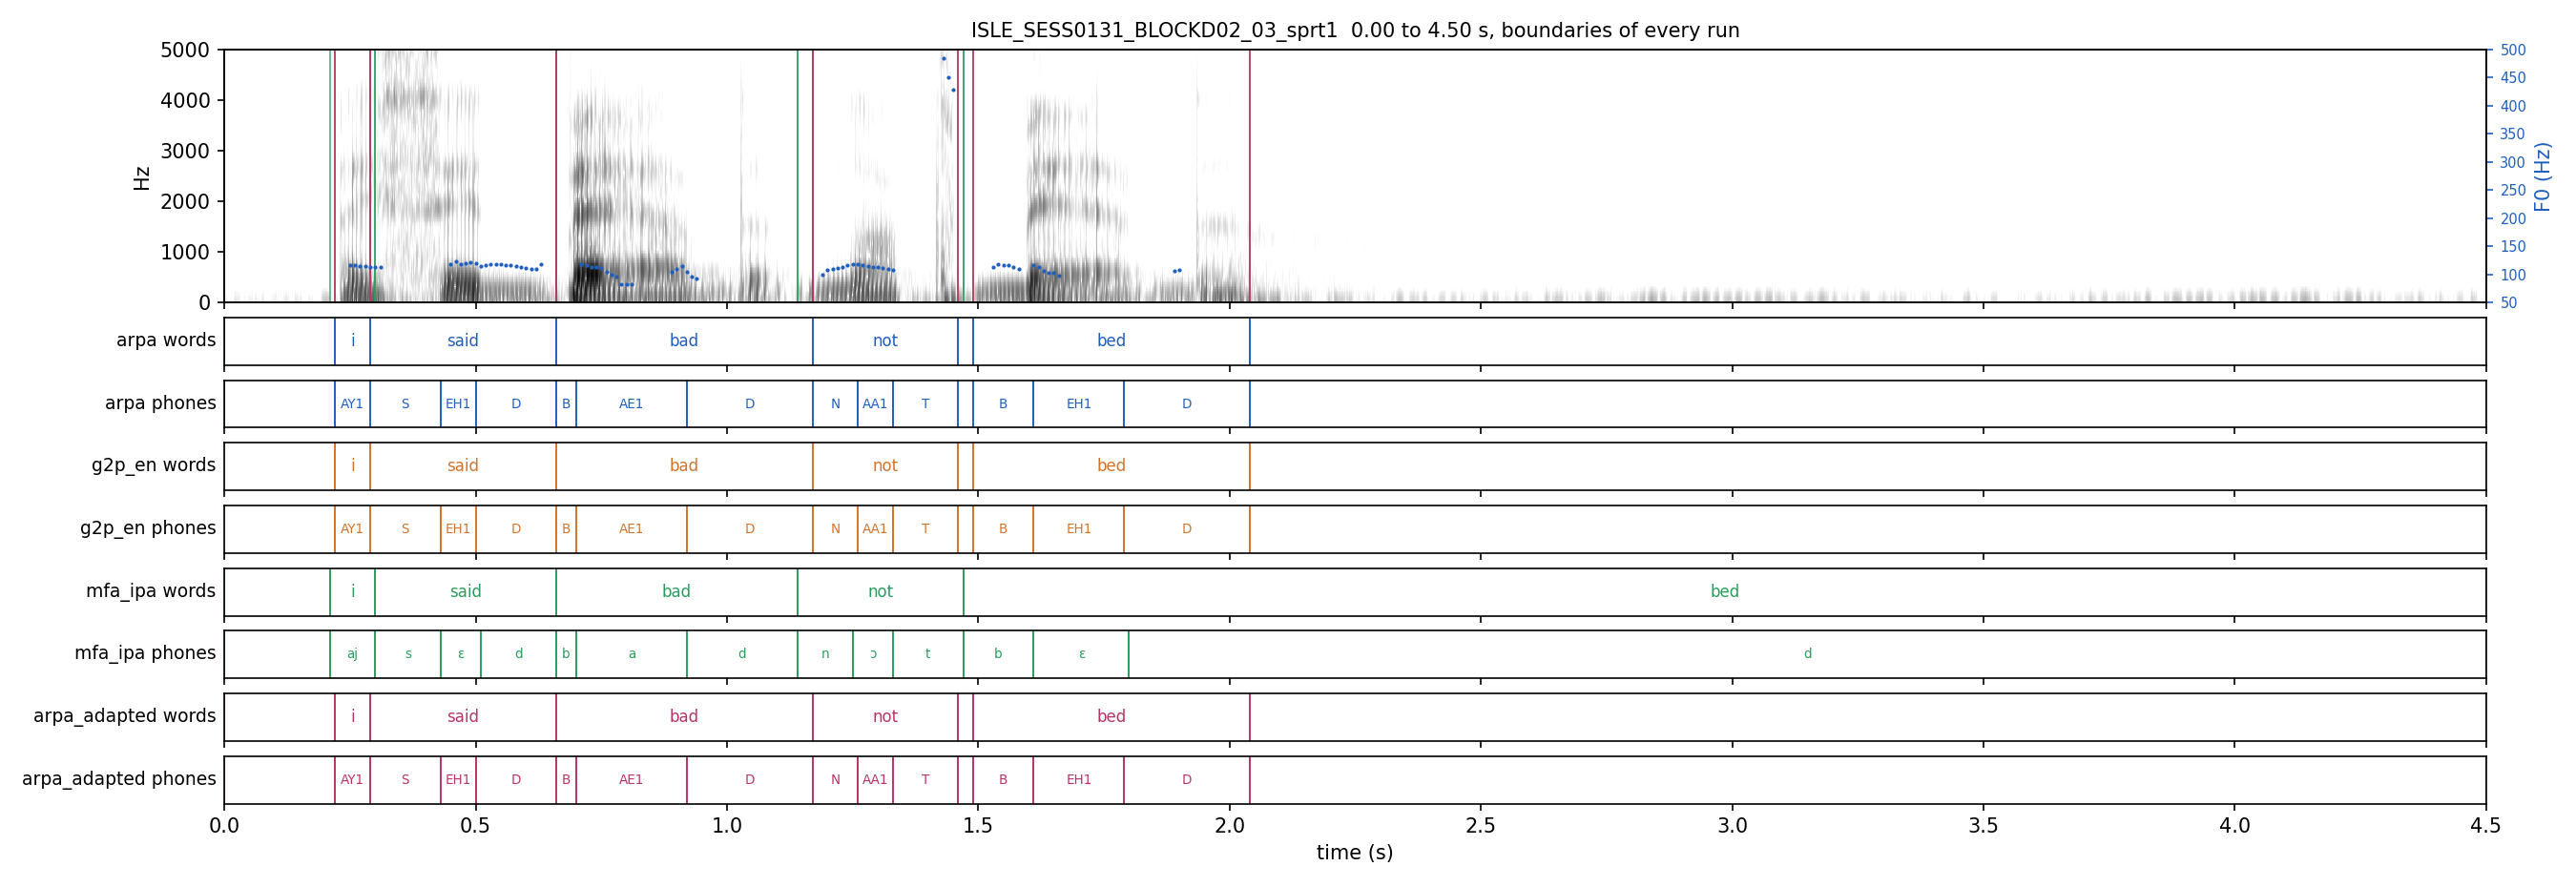

F2BJRLP1_zoom1.png


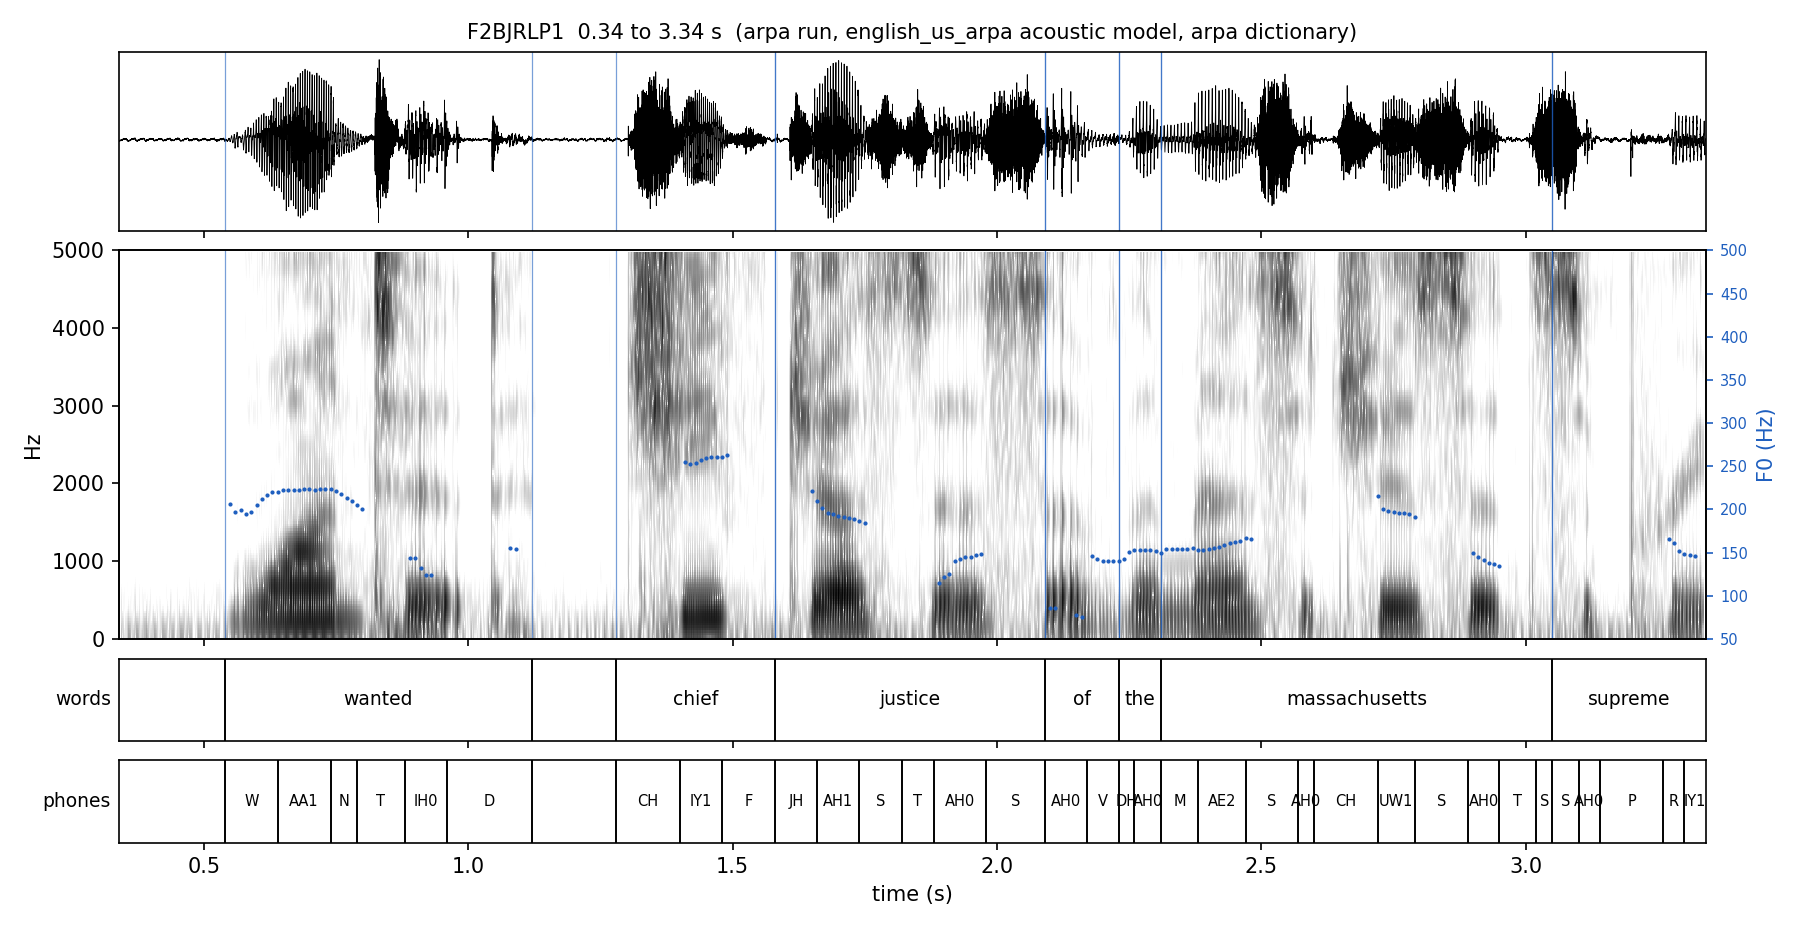

F2BJRLP1_overview.png


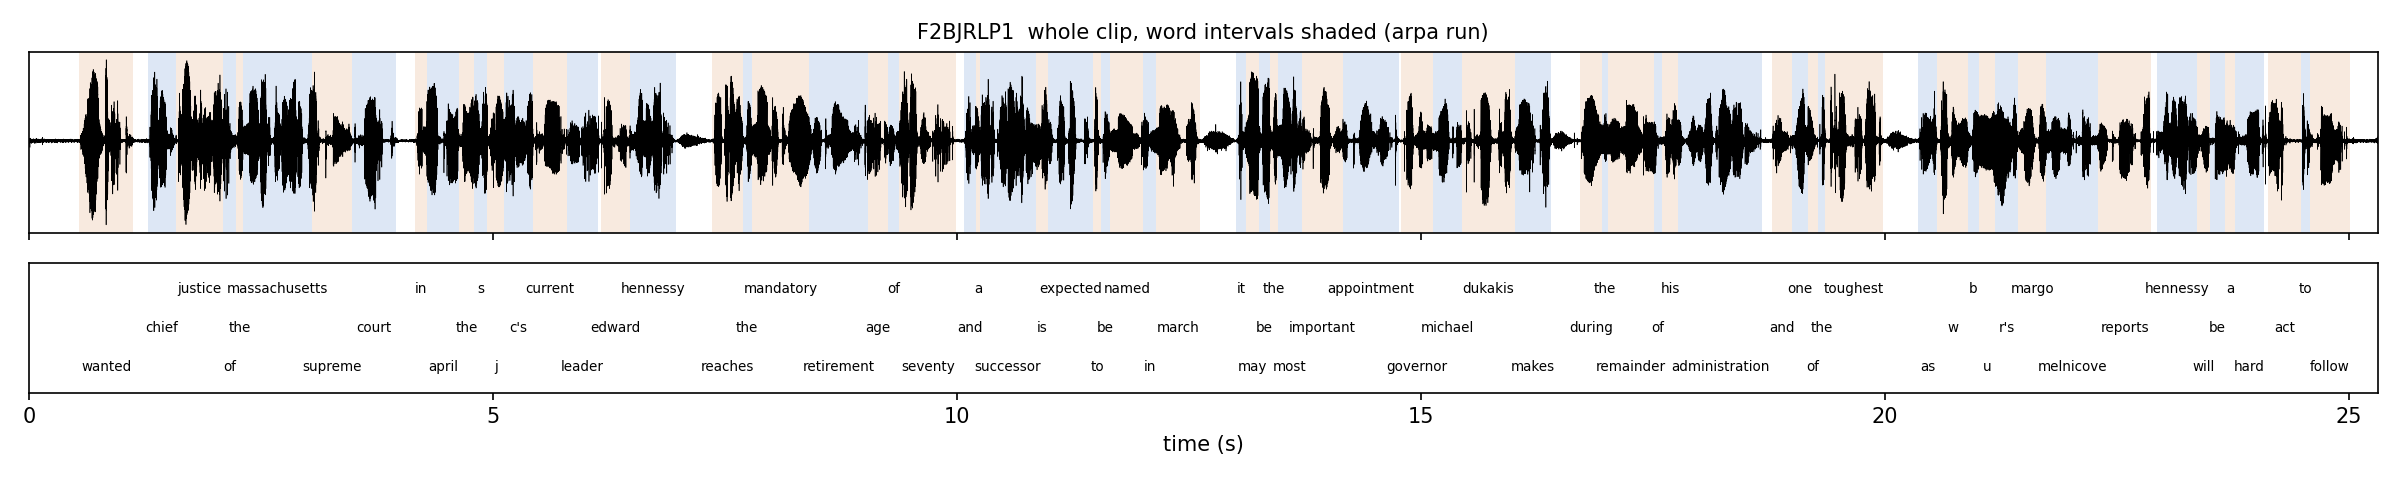

[2026-11-18 00:01:42 IST] finished in 30.8 s


In [9]:
run(f"{PY} align.py --stage plot")
from IPython.display import Image, display
for f in ["ISLE_SESS0131_BLOCKD02_03_sprt1_runs.png", "F2BJRLP1_zoom1.png", "F2BJRLP1_overview.png"]:
    print(f)
    display(Image(f"outputs/figures/{f}"))

## Upload

In [10]:
from huggingface_hub import HfApi

%cd /content/project/Assignment_2a
with zipfile.ZipFile("/content/A2a_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for top in ["outputs", "dictionaries"]:
        for d, _, files in os.walk(top):
            for f in files:
                if not f.endswith(".zip"):          # the adapted acoustic model stays out (about 50 MB)
                    z.write(os.path.join(d, f))
    for d, _, files in os.walk("corpus"):
        for f in files:
            if f.endswith(".lab"):
                z.write(os.path.join(d, f))
log(f"A2a_outputs.zip {os.path.getsize('/content/A2a_outputs.zip') / 1e6:.1f} MB")
ARTIFACTS.append("/content/A2a_outputs.zip")
to_drive("/content/A2a_outputs.zip")                # Drive first, so a failed upload loses nothing
try:
    HfApi().upload_file(path_or_fileobj="/content/A2a_outputs.zip", path_in_repo="results/A2a_outputs.zip",
                        repo_id=DATA_REPO, repo_type="dataset")
    log("uploaded results/A2a_outputs.zip")
except Exception as e:
    log(f"Hugging Face upload failed ({type(e).__name__} {e}), the zip is in Google Drive")

/content/project/Assignment_2a
[2026-11-18 00:01:43 IST] A2a_outputs.zip 5.2 MB
[2026-11-18 00:01:46 IST] uploaded results/A2a_outputs.zip
[2026-11-18 00:01:46 IST] finished in 4.1 s


## Save and disconnect

Saves the executed notebook, the logs, the cell timings and the results to Hugging Face and Google Drive, then
disconnects and deletes this runtime.

In [ ]:
finish("completed")

[2026-11-18 00:01:46 IST] notebook completed after 7.4 min, saving
